Videos → MediaPipe joints → knee angles → two graphs → DTW → GOOD/BAD (5° inward rule)

## 1 Instal libraries

In [3]:

%pip install -q "mediapipe>=0.10.20,<0.11" opencv-python-headless numpy pandas matplotlib scipy


## 2 Import libraries

In [4]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mediapipe as mp
import urllib.request
import os

from scipy.signal import savgol_filter, find_peaks
from google.colab import files
from IPython.display import display, Video

print("All libraries imported successfully!")


All libraries imported successfully!


## 3 Download the pretrained MediaPipe model

In [5]:
MODEL = "pose_landmarker_lite.task"

if not os.path.exists(MODEL):
    urllib.request.urlretrieve(
        "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_lite/float16/1/pose_landmarker_lite.task",
        MODEL
    )

print("MediaPipe model is ready!")


MediaPipe model is ready!


## 4 Upload the first video (GOOD)

In [6]:
print("Please upload your GOOD squat video.")

good_upload = files.upload()

good_video = list(good_upload.keys())[0]

print("First video uploaded:", good_video)


Please upload your GOOD squat video.


Saving IMG_3025.mov to IMG_3025.mov
First video uploaded: IMG_3025.mov


## 5 Upload the second video (BAD)

In [7]:
print("Please upload your BAD squat video.")

bad_upload = files.upload()

bad_video = list(bad_upload.keys())[0]

print("Second video uploaded:", bad_video)


Please upload your BAD squat video.


Saving IMG_3026.mov to IMG_3026.mov
Second video uploaded: IMG_3026.mov


## 6 Check both video

In [8]:
print("Good video:", good_video)
print("Bad video:", bad_video)

print("Good video exists:", os.path.exists(good_video))
print("Bad video exists:", os.path.exists(bad_video))


Good video: IMG_3025.mov
Bad video: IMG_3026.mov
Good video exists: True
Bad video exists: True


## 7 Read video information using OpenCV

In [9]:
def video_info(filename):

    cap = cv2.VideoCapture(filename)

    fps = cap.get(cv2.CAP_PROP_FPS)

    frames = cap.get(cv2.CAP_PROP_FRAME_COUNT)

    width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)

    height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)

    duration = frames / fps

    cap.release()

    print("Video:", filename)
    print("FPS:", fps)
    print("Total frames:", frames)
    print("Duration:", round(duration, 2), "seconds")
    print("Resolution:", int(width), "x", int(height))
    print("-------------------------")

video_info(good_video)
video_info(bad_video)


Video: IMG_3025.mov
FPS: 30.05985369097761
Total frames: 226.0
Duration: 7.52 seconds
Resolution: 1080 x 1920
-------------------------
Video: IMG_3026.mov
FPS: 30.02124144441822
Total frames: 212.0
Duration: 7.06 seconds
Resolution: 1080 x 1920
-------------------------


## 8 Create the MediaPipe detector

In [10]:
BaseOptions = mp.tasks.BaseOptions
PoseLandmarker = mp.tasks.vision.PoseLandmarker
PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions

options = PoseLandmarkerOptions(
    base_options=BaseOptions(model_asset_path=MODEL),
    running_mode=mp.tasks.vision.RunningMode.IMAGE,
    num_poses=1
)

print("MediaPipe detector is ready!")


MediaPipe detector is ready!


## 9 Extract one frame from a video

In [23]:
def get_frame(filename, time_seconds=3):

    cap = cv2.VideoCapture(filename)

    cap.set(cv2.CAP_PROP_POS_MSEC, time_seconds * 1000)

    success, frame = cap.read()

    cap.release()

    if not success:
        raise ValueError("Could not read video frame.")

    return frame

print("Frame extraction function created!")


Frame extraction function created!


## 10 Detect and draw the right-leg joints

In [24]:
def detect_joints(frame):

    # Convert BGR image to RGB
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # Convert the image into MediaPipe format
    image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    # Create detector and detect landmarks
    with PoseLandmarker.create_from_options(options) as detector:
        result = detector.detect(image)

    if not result.pose_landmarks:
        print("No person detected.")
        return frame

    # Get detected body landmarks
    landmarks = result.pose_landmarks[0]

    height, width = frame.shape[:2]

    # Convert landmark coordinates to pixels
    def point(index):
        landmark = landmarks[index]
        x = int(landmark.x * width)
        y = int(landmark.y * height)
        return (x, y)

    # Right-leg landmarks
    hip = point(24)
    knee = point(26)
    ankle = point(28)

    # Draw green lines
    cv2.line(frame, hip, knee, (0, 255, 0), 3)
    cv2.line(frame, knee, ankle, (0, 255, 0), 3)

    # Draw red joint markers
    for joint in [hip, knee, ankle]:
        cv2.circle(frame, joint, 7, (0, 0, 255), -1)

    return frame

print("Joint detection function created!")


Joint detection function created!


## 11 Apply MediaPipe to both videos

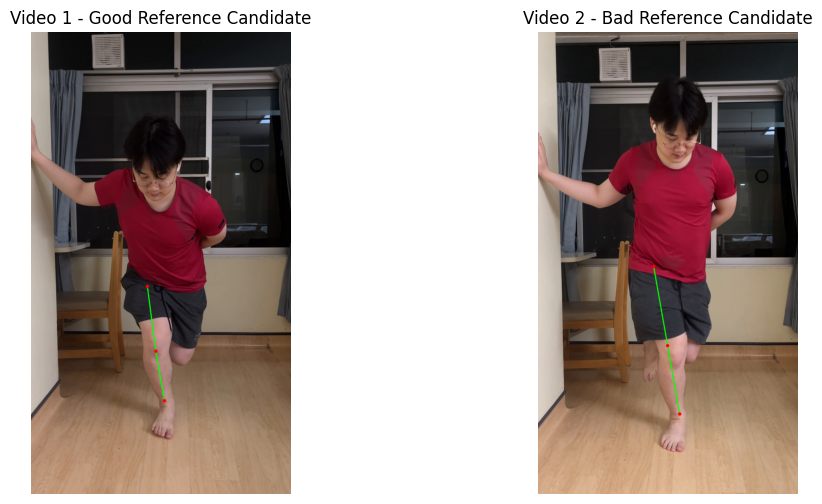

In [25]:
# Extract a frame from each video
good_frame = get_frame(good_video)
bad_frame = get_frame(bad_video)

# Detect the right-leg joints
good_result = detect_joints(good_frame)
bad_result = detect_joints(bad_frame)

# Display the results side by side
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(good_result, cv2.COLOR_BGR2RGB))
plt.title("Video 1 - Good Reference Candidate")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(bad_result, cv2.COLOR_BGR2RGB))
plt.title("Video 2 - Bad Reference Candidate")
plt.axis("off")

plt.show()


## 12 Create a function to calculate the knee angle

In [26]:

# Calculate angle between three joints

def calculate_angle(hip, knee, ankle):

    v1 = hip - knee
    v2 = ankle - knee

    cosine = np.dot(v1, v2) / (
        np.linalg.norm(v1) * np.linalg.norm(v2)
    )

    angle = np.degrees(
        np.arccos(np.clip(cosine, -1, 1))
    )

    return angle

print("Knee angle function created!")


Knee angle function created!


## 13 Extract the joint coordinates

In [27]:
def get_joints(frame):

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    image = mp.Image(
        image_format=mp.ImageFormat.SRGB,
        data=rgb
    )

    with PoseLandmarker.create_from_options(options) as detector:
        result = detector.detect(image)

    if not result.pose_landmarks:
        return None

    landmarks = result.pose_landmarks[0]

    height, width = frame.shape[:2]

    def point(index):
        p = landmarks[index]
        return np.array([p.x * width, p.y * height])

    right_hip = point(24)
    right_knee = point(26)
    right_ankle = point(28)
    left_hip = point(23)

    return right_hip, right_knee, right_ankle, left_hip

print("Joint coordinate function created!")


Joint coordinate function created!


## 15 Calculate inward and outward knee deviation

In [28]:
def calculate_deviation(hip, knee, ankle, opposite_hip):

    # Calculate knee angle
    angle = calculate_angle(hip, knee, ankle)

    # Deviation magnitude
    magnitude = 180 - angle

    # Find reference-line position at knee height
    fraction = (knee[1] - hip[1]) / (ankle[1] - hip[1])

    reference_x = hip[0] + fraction * (ankle[0] - hip[0])

    # Determine inward direction
    inward_direction = np.sign(opposite_hip[0] - hip[0])

    # Horizontal knee displacement relative to reference
    offset = (knee[0] - reference_x) * inward_direction

    # Positive = inward, negative = outward
    deviation = magnitude * np.sign(offset)

    return angle, deviation

print("Signed knee deviation function created!")


Signed knee deviation function created!


## 16 Calculate the angles for both videos

In [29]:
def analyze_frame(frame):

    joints = get_joints(frame)

    if joints is None:
        print("No joints detected.")
        return

    hip, knee, ankle, opposite_hip = joints

    angle, deviation = calculate_deviation(
        hip, knee, ankle, opposite_hip
    )

    print(f"Knee angle: {angle:.2f} degrees")
    print(f"Signed knee deviation: {deviation:.2f} degrees")

    if deviation > 0:
        print("Direction: INWARD")
    elif deviation < 0:
        print("Direction: OUTWARD")
    else:
        print("Direction: STRAIGHT")


print("VIDEO 1 - GOOD REFERENCE CANDIDATE")
analyze_frame(good_frame)

print("----------------------------")

print("VIDEO 2 - BAD REFERENCE CANDIDATE")
analyze_frame(bad_frame)


VIDEO 1 - GOOD REFERENCE CANDIDATE
Knee angle: 174.89 degrees
Signed knee deviation: -5.11 degrees
Direction: OUTWARD
----------------------------
VIDEO 2 - BAD REFERENCE CANDIDATE
Knee angle: 178.07 degrees
Signed knee deviation: 1.93 degrees
Direction: INWARD


## 17 Create a function to analyze an entire video

In [30]:
def analyze_video(filename):

    cap = cv2.VideoCapture(filename)

    if not cap.isOpened():
        raise ValueError("Cannot open video: " + filename)

    fps = cap.get(cv2.CAP_PROP_FPS)

    if fps <= 0:
        cap.release()
        raise ValueError("Cannot read video FPS.")

    times = []
    angles = []
    deviations = []

    options_video = PoseLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=MODEL),
        running_mode=mp.tasks.vision.RunningMode.VIDEO,
        num_poses=1
    )

    frame_number = 0

    with PoseLandmarker.create_from_options(options_video) as detector:

        while True:

            success, frame = cap.read()

            if not success:
                break

            height, width = frame.shape[:2]

            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

            image = mp.Image(
                image_format=mp.ImageFormat.SRGB,
                data=rgb
            )

            timestamp = int(frame_number * 1000 / fps)

            result = detector.detect_for_video(image, timestamp)

            if result.pose_landmarks:

                lm = result.pose_landmarks[0]

                def point(index):
                    p = lm[index]
                    return np.array([p.x * width, p.y * height])

                hip = point(24)
                knee = point(26)
                ankle = point(28)
                opposite_hip = point(23)

                try:
                    angle, deviation = calculate_deviation(
                        hip, knee, ankle, opposite_hip
                    )
                except (ValueError, ZeroDivisionError, FloatingPointError):
                    angle = np.nan
                    deviation = np.nan

                if not np.isfinite(angle):
                    angle = np.nan

                if not np.isfinite(deviation):
                    deviation = np.nan

            else:
                angle = np.nan
                deviation = np.nan

            times.append(frame_number / fps)
            angles.append(angle)
            deviations.append(deviation)

            frame_number += 1

    cap.release()

    df = pd.DataFrame({
        "Time": times,
        "Knee Angle": angles,
        "Knee Deviation": deviations
    })

    return df

print("Video analysis function created!")


Video analysis function created!


## 18 Apply the function to both squat videos

In [31]:
good_df = analyze_video(good_video)

bad_df = analyze_video(bad_video)

print("Both videos analyzed successfully!")

print("\nGOOD VIDEO:")
display(good_df.head())

print("\nBAD VIDEO:")
display(bad_df.head())


Both videos analyzed successfully!

GOOD VIDEO:


,Time,Knee Angle,Knee Deviation
0,0.000000,177.058997,-2.941003
1,0.033267,175.606307,-4.393693
2,0.066534,174.724714,-5.275286
3,0.099801,174.328868,-5.671132
4,0.133068,173.114676,-6.885324



BAD VIDEO:


,Time,Knee Angle,Knee Deviation
0,0.000000,174.545997,-5.454003
1,0.033310,174.517501,-5.482499
2,0.066619,174.240779,-5.759221
3,0.099929,174.059439,-5.940561
4,0.133239,173.589840,-6.410160


## 19 Plot Knee Angle vs. Time

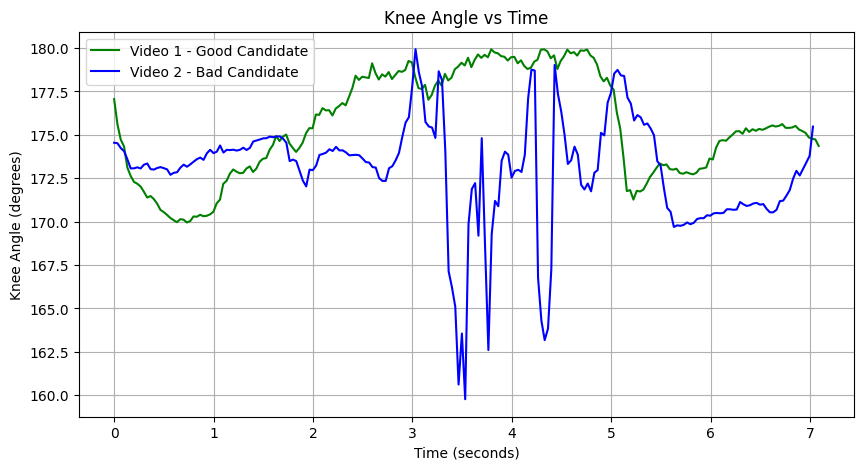

In [32]:
plt.figure(figsize=(10, 5))

plt.plot(
    good_df["Time"],
    good_df["Knee Angle"],
    label="Video 1 - Good Candidate",
    color="green"
)

plt.plot(
    bad_df["Time"],
    bad_df["Knee Angle"],
    label="Video 2 - Bad Candidate",
    color="blue"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Knee Angle (degrees)")
plt.title("Knee Angle vs Time")

plt.legend()
plt.grid(True)
plt.show()


##20 Plot Signed Knee Deviation vs. Time

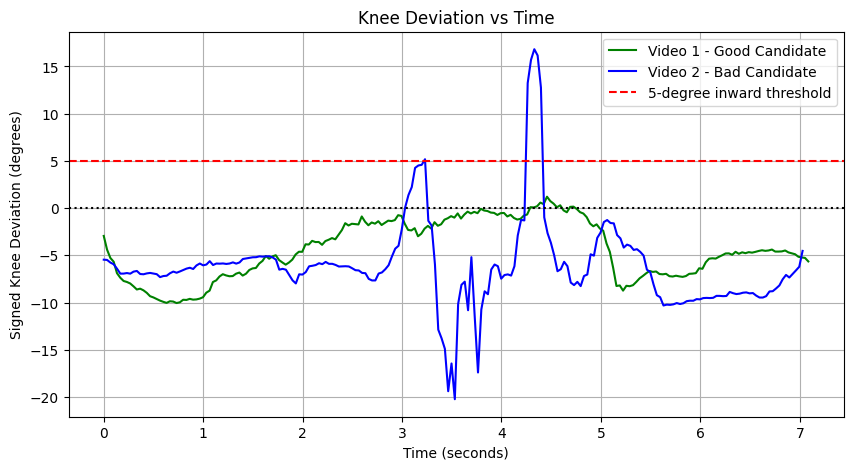

In [33]:
plt.figure(figsize=(10, 5))

plt.plot(
    good_df["Time"],
    good_df["Knee Deviation"],
    label="Video 1 - Good Candidate",
    color="green"
)

plt.plot(
    bad_df["Time"],
    bad_df["Knee Deviation"],
    label="Video 2 - Bad Candidate",
    color="blue"
)

# Professor's 5-degree threshold
plt.axhline(
    y=5,
    color="red",
    linestyle="--",
    label="5-degree inward threshold"
)

# Zero represents straight projected alignment
plt.axhline(
    y=0,
    color="black",
    linestyle=":"
)

plt.xlabel("Time (seconds)")
plt.ylabel("Signed Knee Deviation (degrees)")
plt.title("Knee Deviation vs Time")

plt.legend()
plt.grid(True)
plt.show()


## 21 Save both tables as CSV files

In [34]:
good_df.to_csv("good_squat_angles.csv", index=False)

bad_df.to_csv("bad_squat_angles.csv", index=False)

print("Both CSV files saved successfully!")


Both CSV files saved successfully!


## 22 Prepare the two knee-deviation sequences

In [35]:
good_curve = good_df["Knee Deviation"].dropna().to_numpy()

bad_curve = bad_df["Knee Deviation"].dropna().to_numpy()

print("Video 1 measurements:", len(good_curve))
print("Video 2 measurements:", len(bad_curve))


Video 1 measurements: 214
Video 2 measurements: 212


## 23 Smooth the curves and prepare them for comparison

In [36]:
def prepare_curve(df):

    # Fill missing measurements
    curve = df["Knee Deviation"].interpolate(
        limit_direction="both"
    )

    # Smooth the measurements
    curve = curve.rolling(
        window=5,
        center=True,
        min_periods=1
    ).median()

    # Convert to a NumPy array
    curve = curve.to_numpy()

    # Make sure valid measurements exist
    if not np.isfinite(curve).all():
        raise ValueError("Some knee measurements are missing.")

    # Reduce to 100 points for faster DTW
    old_time = np.linspace(0, 1, len(curve))
    new_time = np.linspace(0, 1, 100)

    curve = np.interp(new_time, old_time, curve)

    return curve


good_curve = prepare_curve(good_df)
bad_curve = prepare_curve(bad_df)

print("Good curve:", len(good_curve), "points")
print("Bad curve:", len(bad_curve), "points")


Good curve: 100 points
Bad curve: 100 points


## 24 Calculate the DTW distance

In [37]:
def calculate_dtw(a, b):

    n = len(a)
    m = len(b)

    # Create a cost table
    D = np.full((n + 1, m + 1), np.inf)

    # Starting position
    D[0, 0] = 0

    # Compare all pairs of points
    for i in range(1, n + 1):
        for j in range(1, m + 1):

            cost = abs(a[i - 1] - b[j - 1])

            D[i, j] = cost + min(
                D[i - 1, j],
                D[i, j - 1],
                D[i - 1, j - 1]
            )

    # Trace the best matching path
    i, j = n, m
    path = []

    while i > 0 and j > 0:
        path.append((i - 1, j - 1))

        choices = [
            D[i - 1, j],
            D[i, j - 1],
            D[i - 1, j - 1]
        ]

        step = np.argmin(choices)

        if step == 0:
            i -= 1
        elif step == 1:
            j -= 1
        else:
            i -= 1
            j -= 1

    path.reverse()

    # Average difference along the best path
    distance = D[n, m] / len(path)

    return distance, path


dtw_distance, dtw_path = calculate_dtw(
    good_curve, bad_curve
)

print(f"DTW Distance: {dtw_distance:.2f} degrees")
print("Matching pairs:", len(dtw_path))


DTW Distance: 1.44 degrees
Matching pairs: 167


## 25 Plot the DTW comparison

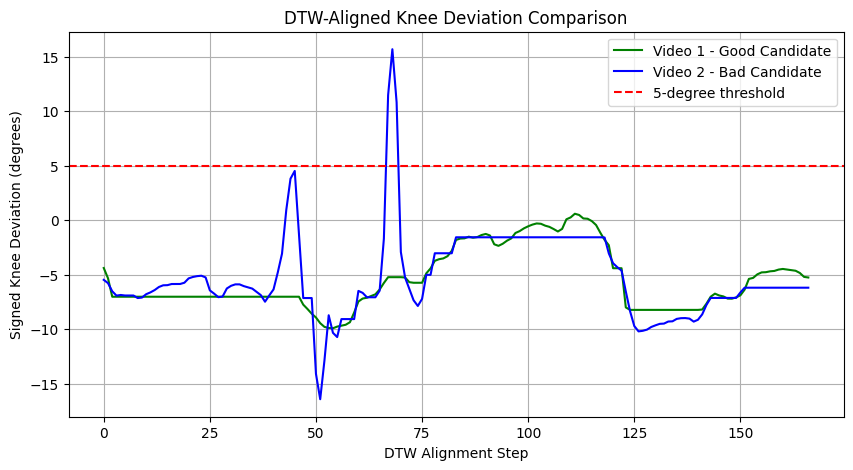

In [38]:
# Get matching point positions
good_indices = [i for i, j in dtw_path]
bad_indices = [j for i, j in dtw_path]

# Use the DTW matching path to align the curves
good_aligned = good_curve[good_indices]
bad_aligned = bad_curve[bad_indices]

plt.figure(figsize=(10, 5))

plt.plot(
    good_aligned,
    label="Video 1 - Good Candidate",
    color="green"
)

plt.plot(
    bad_aligned,
    label="Video 2 - Bad Candidate",
    color="blue"
)

plt.axhline(
    y=5,
    color="red",
    linestyle="--",
    label="5-degree threshold"
)

plt.xlabel("DTW Alignment Step")
plt.ylabel("Signed Knee Deviation (degrees)")
plt.title("DTW-Aligned Knee Deviation Comparison")

plt.legend()
plt.grid(True)
plt.show()


##26 Display a simple DTW results summary

In [39]:
print("DYNAMIC TIME WARPING RESULTS")
print("----------------------------")

print("Reference video:", good_video)
print("Test video:", bad_video)

print(f"DTW distance: {dtw_distance:.2f} degrees")

print("Interpretation:")
print("Smaller DTW distance = more similar knee movement")

print("\nDTW comparison completed!")


DYNAMIC TIME WARPING RESULTS
----------------------------
Reference video: IMG_3025.mov
Test video: IMG_3026.mov
DTW distance: 1.44 degrees
Interpretation:
Smaller DTW distance = more similar knee movement

DTW comparison completed!


## 27 Create the classification function

In [40]:
THRESHOLD = 5

def classify_squat(df):

    # Check how many valid measurements we have
    valid = df["Knee Deviation"].dropna()

    if len(valid) == 0:
        return np.nan, "UNABLE TO ASSESS"

    # Smooth the knee deviation
    smooth = df["Knee Deviation"].rolling(
        window=5,
        center=True,
        min_periods=3
    ).median()

    # Find maximum inward deviation
    max_inward = max(0, smooth.max())

    # Apply the 5-degree rule
    if max_inward > THRESHOLD:
        result = "BAD"
    else:
        result = "GOOD"

    return max_inward, result

print("Classification function created!")


Classification function created!


## 28 Classify both squat videos

In [41]:
good_max, good_result = classify_squat(good_df)

bad_max, bad_result = classify_squat(bad_df)

print("VIDEO 1:", good_video)
print(f"Maximum inward deviation: {good_max:.2f} degrees")
print("Classification:", good_result)

print("------------------------------")

print("VIDEO 2:", bad_video)
print(f"Maximum inward deviation: {bad_max:.2f} degrees")
print("Classification:", bad_result)


VIDEO 1: IMG_3025.mov
Maximum inward deviation: 0.59 degrees
Classification: GOOD
------------------------------
VIDEO 2: IMG_3026.mov
Maximum inward deviation: 15.69 degrees
Classification: BAD


## 29 Create the final results table

In [42]:
results = pd.DataFrame({
    "Video": [good_video, bad_video],
    "Maximum Inward Deviation (deg)": [
        good_max, bad_max
    ],
    "Threshold (deg)": [THRESHOLD, THRESHOLD],
    "Classification": [
        good_result, bad_result
    ]
})

display(results)


,Video,Maximum Inward Deviation (deg),Threshold (deg),Classification
0,IMG_3025.mov,0.587351,5,GOOD
1,IMG_3026.mov,15.692151,5,BAD


## 30 Display the final graph with the results

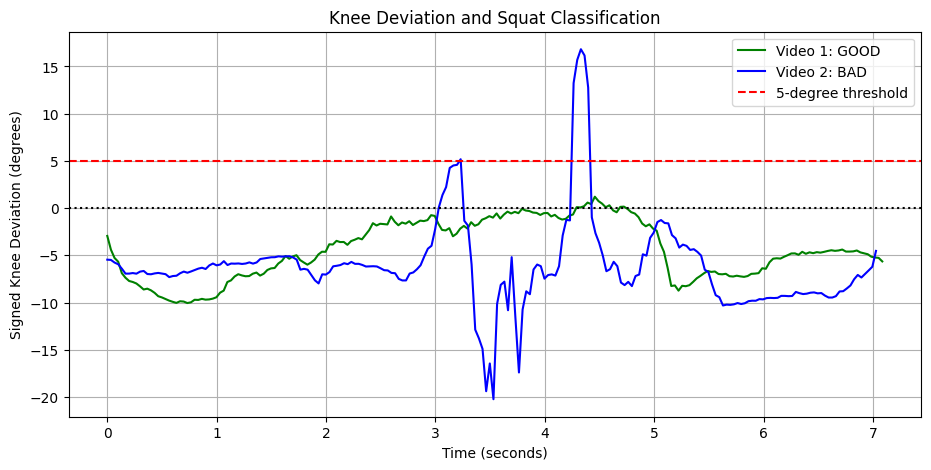

In [43]:
plt.figure(figsize=(11, 5))

plt.plot(
    good_df["Time"],
    good_df["Knee Deviation"],
    color="green",
    label=f"Video 1: {good_result}"
)

plt.plot(
    bad_df["Time"],
    bad_df["Knee Deviation"],
    color="blue",
    label=f"Video 2: {bad_result}"
)

plt.axhline(
    THRESHOLD,
    color="red",
    linestyle="--",
    label="5-degree threshold"
)

plt.axhline(
    0,
    color="black",
    linestyle=":"
)

plt.title("Knee Deviation and Squat Classification")
plt.xlabel("Time (seconds)")
plt.ylabel("Signed Knee Deviation (degrees)")

plt.legend()
plt.grid(True)
plt.show()


## 31 Save the final results

In [44]:
results.to_csv("final_squat_results.csv", index=False)

print("Final results saved successfully!")

Final results saved successfully!
